# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [44]:

# Import the libraries you need for:

# - data handling
import pandas as pd
import numpy as np

# - plotting
import matplotlib.pyplot as plt

# - text preprocessing
import re
import string
import contractions 
# - tokenization / stopwords / lemmatization
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# - counting words and bigrams
from collections import Counter
from nltk.util import ngrams

print("All libraries imported successfully.")


All libraries imported successfully.


In [2]:

#Download any required NLTK resources.

# Download English stopwords for removing common words
nltk.download("stopwords")

# Download WordNet for lemmatisation
nltk.download("wordnet")

# Download additional WordNet language data
nltk.download("omw-1.4")

print("NLTK resources downloaded successfully.")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...


NLTK resources downloaded successfully.


In [ ]:

#: Load the dataset.
# The CSV file contains the customer reviews we will analyse.

df = pd.read_csv("amazon_reviews_lab.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


#### 1.1 Exploring the Dataset

We inspect the dataset's size, columns, missing values, and customer rating distribution to understand the data before preprocessing.

In [8]:

# Check the number of rows and columns.
print("Dataset shape:", df.shape)

# Inspect the column names and data types.
display(df.info())

# Count missing values in each column.
print("\nMissing values:")
display(df.isnull().sum())

# Examine the distribution of customer ratings.
print("\nRating counts:")
display(df["rating"].value_counts().sort_index())


Dataset shape: (997, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    object 
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    object 
 3   review_summary       997 non-null    object 
 4   review_time_raw      997 non-null    object 
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    object 
 7   sentiment_label      997 non-null    object 
 8   review_length_words  997 non-null    int64  
 9   processed_tokens     997 non-null    object 
dtypes: float64(1), int64(2), object(7)
memory usage: 78.0+ KB


None


Missing values:


product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
processed_tokens       0
dtype: int64


Rating counts:


rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

#### Interpretation of Dataset Exploration

The dataset contains **997 customer reviews and 9 columns**, covering review text, ratings, timestamps, and sentiment-related information.

There are **no missing values** in any column, so no missing-value imputation is required at this stage.

The rating distribution is uneven: **580 reviews have a rating of 5**, making five-star reviews the most common, while **48 reviews have a rating of 2**, making two-star reviews the least common. This indicates that the dataset contains more highly rated reviews than lower-rated reviews.

#### 1.2 Preparing Text Preprocessing Tools

We load English stopwords to remove common words that add little analytical value and initialise a lemmatiser to reduce words to their base forms.

In [54]:

# Prepare the tools for text preprocessing

stop_words = set(stopwords.words("english"))

# Preserve negation words because they affect review meaning
negation_words = {"no", "not", "never", "nor", "cannot"}

# Initialize the lemmatizer
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Handle missing reviews
    if pd.isna(text):
        return []

    # Convert text to lowercase
    text = str(text).lower()

    # Expand contractions, e.g. "don't" becomes "do not"
    text = contractions.fix(text)

    # Standardize the full name and abbreviation
    text = re.sub(
    r"\bbarnes\s*&\s*noble\b|\bb\s*&\s*n\b",
    "barnes noble",
    text
)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove punctuation, numbers, and other non-letter characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Split text into individual words
    tokens = wordpunct_tokenize(text)

    # Remove stopwords while preserving negations, then lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word.isalpha()
        and (word not in stop_words or word in negation_words)
    ]

    return cleaned_tokens


The text preprocessing tools are prepared to clean customer reviews before analysis. Stopwords are identified for removal, while important negation words such as “not” and “never” are preserved because they can change a review's meaning. A lemmatizer is initialized to reduce words to their base forms. The preprocessing function converts text to lowercase, expands contractions, removes URLs and non-letter characters, tokenizes the text, removes unnecessary words, and applies lemmatization. Missing reviews return an empty list to prevent errors during processing.

#### 1.3 Applying Text Preprocessing

We apply the preprocessing function to every customer review and store the cleaned tokens in a new column called `processed_tokens`.

In [55]:

# Apply the preprocessing function to every customer review.
df["processed_tokens"] = df["review_text"].apply(preprocess_text)

# Preview the original reviews and their cleaned tokens.
display(df[["review_text", "processed_tokens"]].head())

# Confirm the number of reviews processed.
print("Reviews processed:", len(df["processed_tokens"]))


,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, not, anyone, especially, fo..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ..."
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, ad, sta..."
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ..."


Reviews processed: 997


All 997 customer reviews were successfully processed into cleaned word lists. These will be used to identify the most frequent words, examine common word pairs such as “battery life” and “touch screen,” and visualize recurring terms to understand which products, features, and experiences customers discuss most often.

#### 1.4 Identifying the Most Common Words

We combine the cleaned tokens from all 997 reviews and count how often each word appears to identify recurring topics in customer feedback.

In [56]:

# Combine all cleaned words into one list.
all_words = [
    word
    for review in df["processed_tokens"]
    for word in review
]

# Count how often each word appears.
word_counts = Counter(all_words)

# Display the 15 most common words.
most_common_words = word_counts.most_common(15)

# Present the results in a table.
word_frequency_df = pd.DataFrame(
    most_common_words,
    columns=["word", "frequency"]
)

display(word_frequency_df)


,word,frequency
0,not,1854
1,nook,1580
2,book,986
3,one,596
4,kindle,592
5,screen,536
6,barnes,490
7,noble,488
8,would,482
9,like,474


The most frequent word is “not” (1,854 occurrences), followed by “nook” (1,580) and “book” (986). “Kindle” (592) and “screen” (536) also appear frequently, indicating that customers often discuss e-readers and device features. The high frequency of “not” partly reflects the expansion of contractions during preprocessing, so it should not be interpreted as entirely negative sentiment.

#### 1.5 Identifying Common Word Pairs (Bigrams)

We group consecutive words into pairs and count their frequency to identify common phrases that provide more context than individual words.

In [57]:

# Generate pairs of consecutive words from the cleaned token list.
all_bigrams = [
    bigram
    for review in df["processed_tokens"]
    for bigram in ngrams(review, 2)
]

# Count how often each word pair appears.
bigram_counts = Counter(all_bigrams)

# Display the 15 most common bigrams.
most_common_bigrams = bigram_counts.most_common(15)

# Convert the results into a readable table.
bigram_frequency_df = pd.DataFrame(
    [
        (" ".join(bigram), frequency)
        for bigram, frequency in most_common_bigrams
    ],
    columns=["bigram", "frequency"]
)

display(bigram_frequency_df)


,bigram,frequency
0,barnes noble,484
1,nook color,135
2,e reader,132
3,battery life,98
4,touch screen,96
5,sd card,90
6,nook hd,80
7,work great,65
8,could not,64
9,nook tablet,64


#### Interpretation of Common Bigrams

The most frequent meaningful word pairs include “barnes noble” (484 occurrences), “nook color” (135), and “e reader” (132). These phrases indicate that customers frequently discuss specific brands and e-reader products. “Battery life” (98) and “touch screen” (96) highlight device features that receive repeated attention.

The phrases “could not” (64) and “would not” (55) also show that customers describe limitations or difficulties. However, the surrounding review text is needed to determine exactly which problems they report.

#### 1.6 Visualising the Most Common Words

We create a horizontal bar chart of the 15 most frequent words to make the main topics in customer reviews easier to compare.

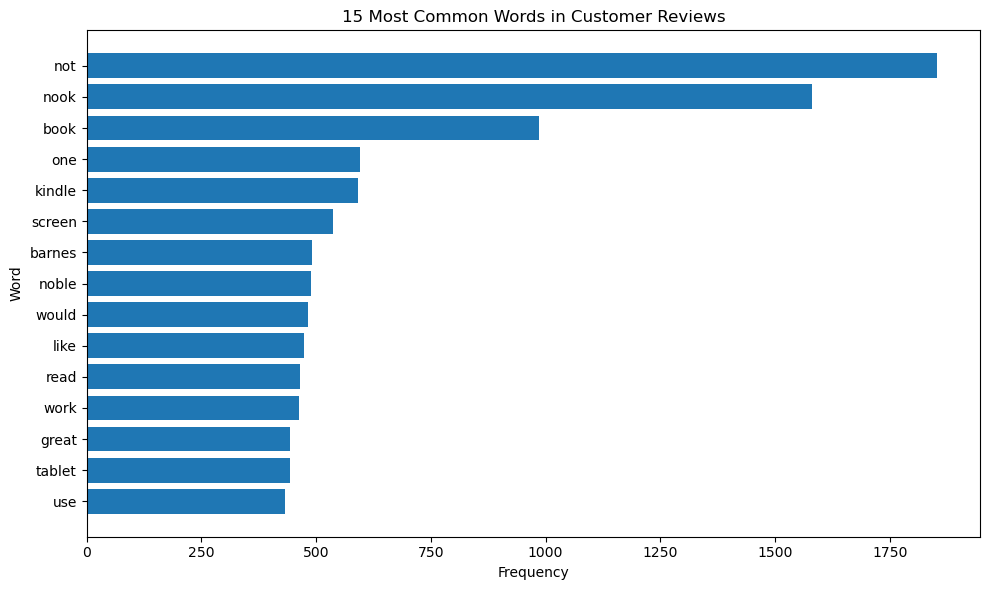

In [58]:

# Create a horizontal bar chart of the most common words.
plt.figure(figsize=(10, 6))

plt.barh(
    word_frequency_df["word"][::-1],
    word_frequency_df["frequency"][::-1]
)

plt.title("15 Most Common Words in Customer Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


#### Interpretation of Word Frequency Visualisation

The bar chart highlights “not,” “nook,” and “book” as the most frequent words in the reviews. Product-related terms such as “kindle,” “screen,” and “tablet” also appear frequently, showing that customers often discuss reading devices and their features.

The chart makes differences in word frequency easy to compare. However, frequent words alone do not determine whether customers are satisfied or dissatisfied.

#### 1.7 Reflection: Customer Sentiment and Product Experience

The frequent mentions of “nook,” “book,” “kindle,” and “screen” suggest that customers focus on reading devices and their functionality. Phrases such as “battery life” and “touch screen” highlight specific product features, while “could not” and “would not” suggest that some reviews describe limitations or difficulties.

The frequent use of “not” indicates that negative statements deserve closer examination. However, word frequencies and bigrams alone cannot establish overall sentiment. Reading reviews in context and comparing them with customer ratings would provide a clearer understanding of customer experiences.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


#### 2.1 Preparing the Time Series Data

We convert the review timestamps into datetime format and inspect the earliest and latest dates to establish the period covered by the dataset.

In [15]:

# Convert timestamps into datetime format.
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# Display the date range covered by the reviews.
print("Earliest review:", df["timestamp"].min())
print("Latest review:", df["timestamp"].max())

# Check for timestamps that could not be converted.
print("Missing timestamps:", df["timestamp"].isna().sum())


Earliest review: 2000-05-12 00:00:00
Latest review: 2014-07-17 00:00:00
Missing timestamps: 0


#### Interpretation of the Date Range

The dataset covers reviews from **12 May 2000 to 17 July 2014**, with no missing timestamps. This provides a period of approximately 14 years for examining changes in review activity and customer ratings over time.

#### 2.2 Aggregating Reviews by Month

We group reviews by month to calculate the total number of reviews and the average customer rating for each month.

In [59]:

# Set the timestamp as the index for monthly resampling.
df_time = df.set_index("timestamp").sort_index()

# Count the number of reviews in each month.
monthly_review_count = df_time["rating"].resample("MS").count()

# Calculate the average rating for each month.
monthly_avg_rating = df_time["rating"].resample("MS").mean()

# Display the first few months of results.
monthly_summary = pd.DataFrame({
    "review_count": monthly_review_count,
    "average_rating": monthly_avg_rating
})

display(monthly_summary.head(10))

# Report the number of monthly periods created.
print("Monthly periods:", len(monthly_summary))


,review_count,average_rating
timestamp,,
2000-05-01,1,2.0
2000-06-01,0,NaN
2000-07-01,0,NaN
2000-08-01,0,NaN
2000-09-01,0,NaN
2000-10-01,0,NaN
2000-11-01,0,NaN
2000-12-01,0,NaN
2001-01-01,0,NaN


Monthly periods: 171


#### Interpretation of Monthly Aggregation

The data spans **171 monthly periods**. May 2000 contains one review with an average rating of 2.0, while the following months shown have no recorded reviews, so their average ratings are undefined (`NaN`). These empty months represent periods without observations, not ratings of zero.

#### 2.3 Monthly Review Activity

We plot the number of reviews recorded each month to identify periods of higher and lower customer review activity.

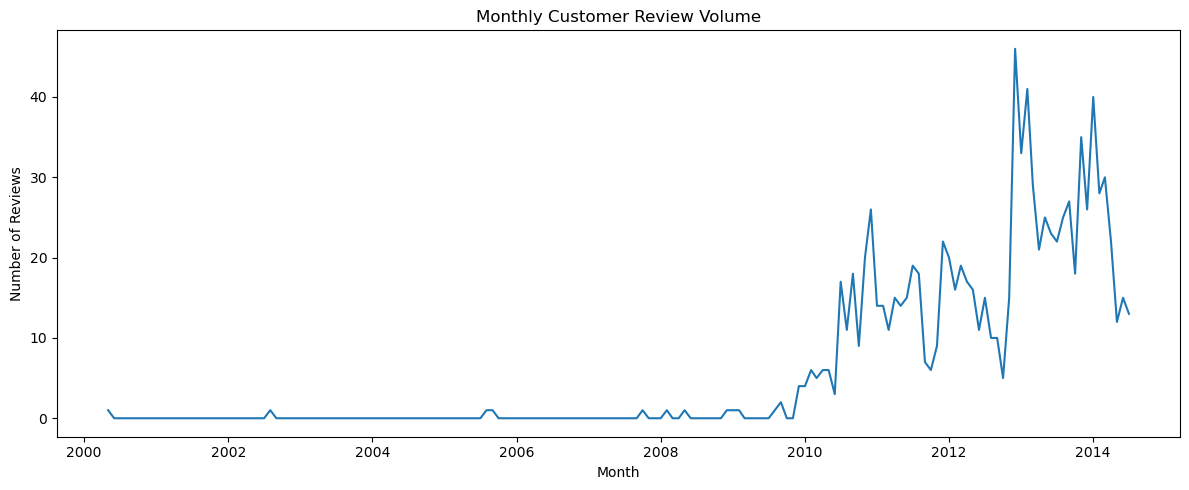

In [60]:

# Plot the number of reviews recorded each month.
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_review_count.index,
    monthly_review_count.values
)

plt.title("Monthly Customer Review Volume")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


#### Interpretation of Monthly Review Volume

Review activity is very low during the early years, with many months recording zero reviews. The number of reviews begins to increase around 2010 and becomes more active between 2011 and 2014. The highest monthly volume occurs around 2012, at approximately 46 reviews. This suggests that review activity increases substantially in the later years of the dataset.

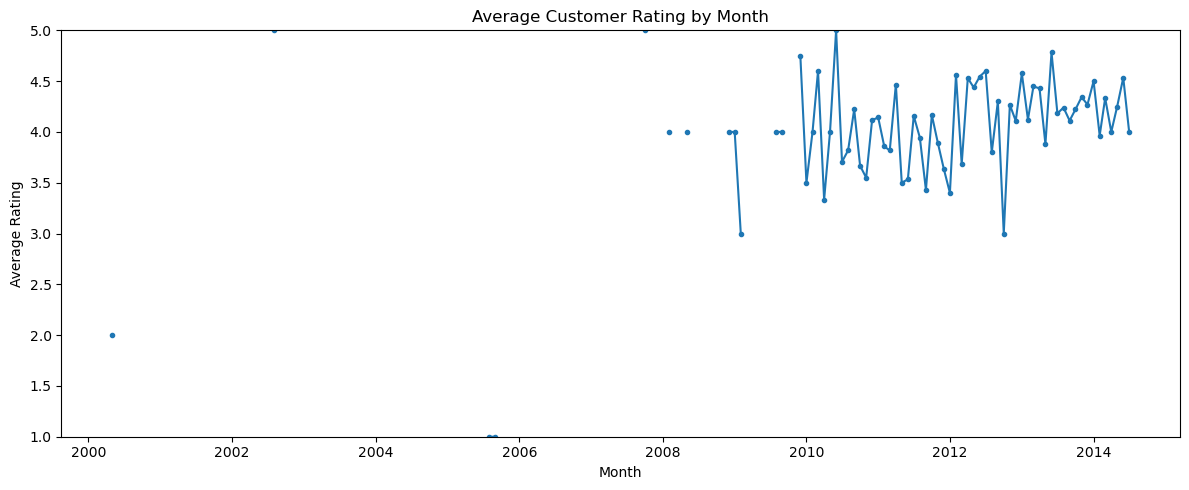

In [61]:
# Plot the average rating for months with recorded reviews.
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_avg_rating.index,
    monthly_avg_rating.values,
    marker="o",
    markersize=3
)

plt.title("Average Customer Rating by Month")
plt.xlabel("Month")
plt.ylabel("Average Rating")
plt.ylim(1, 5)
plt.tight_layout()
plt.show()

#### Interpretation of Monthly Average Ratings

Monthly average ratings fluctuate over time. In the later years, most recorded monthly averages fall between 3.5 and 4.6, suggesting generally favourable customer ratings. Some months show lower averages, around 3.0, while others reach 5.0. However, many early months have no recorded reviews, so the overall trend should be interpreted cautiously.

#### 2.5 Three-Month Rolling Average

We calculate a three-month rolling average to smooth short-term fluctuations in monthly ratings and make the broader pattern easier to observe.

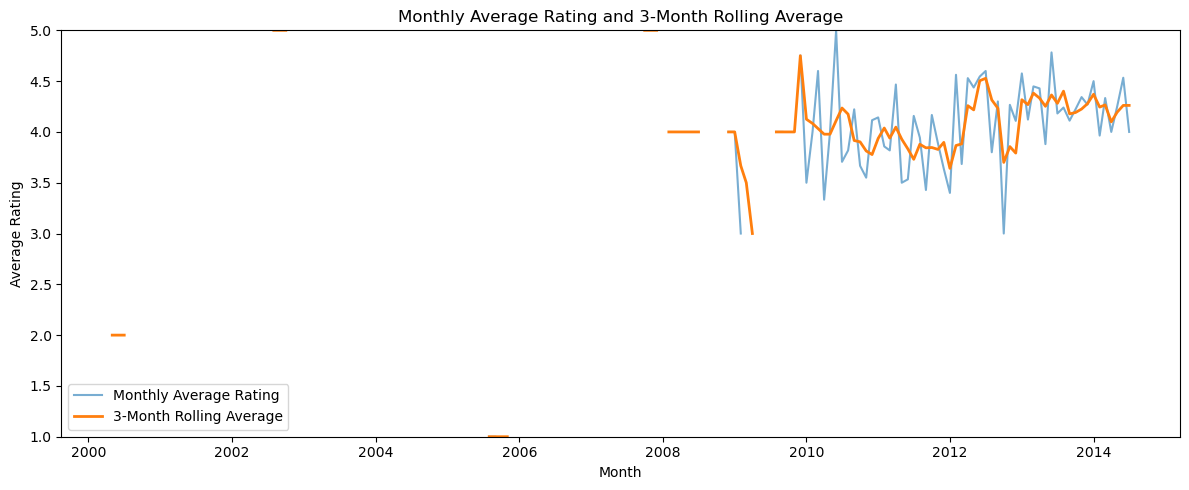

In [62]:
# Calculate the three-month rolling average of monthly ratings.
rolling_avg_rating = monthly_avg_rating.rolling(
    window=3,
    min_periods=1
).mean()

# Plot the monthly average ratings and rolling average together.
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_avg_rating.index,
    monthly_avg_rating.values,
    label="Monthly Average Rating",
    alpha=0.6
)

plt.plot(
    rolling_avg_rating.index,
    rolling_avg_rating.values,
    label="3-Month Rolling Average",
    linewidth=2
)

plt.title("Monthly Average Rating and 3-Month Rolling Average")
plt.xlabel("Month")
plt.ylabel("Average Rating")
plt.ylim(1, 5)
plt.legend()
plt.tight_layout()
plt.show()

#### Interpretation of the Three-Month Rolling Average

The graph shows significant gaps in monthly ratings throughout the 2000s, with more consistent observations emerging around late 2009. From 2010 onward, monthly ratings fluctuate between 3.0 and 5.0. The three-month rolling average smooths these fluctuations and generally stays between 3.7 and 4.5, making the overall pattern easier to observe.

### Overall Reflection

The time-series analysis shows that customer review activity increases substantially from around 2010, reaching its highest monthly volume around 2012. Monthly average ratings fluctuate, but most recorded ratings in the later years are relatively high. The three-month rolling average helps reveal the broader rating pattern by reducing short-term fluctuations. However, the many months without recorded reviews, especially in the earlier years, limit reliable comparisons across the entire period. Therefore, the observed trends should be interpreted cautiously.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


#### 3.1 Import Libraries
The required libraries are imported for text vectorization, data splitting, neural network training, and model evaluation.

In [20]:
# Data handling
import pandas as pd
import numpy as np

# Split data and convert text into numerical features
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Evaluate model performance
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Build the neural network
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Dataset shape:", df.shape)

TensorFlow version: 2.21.0
Dataset shape: (997, 10)


TensorFlow 2.21.0 is available for building and training the neural network. The dataset contains 997 reviews and 10 columns, providing the data needed for the analysis.

#### 3.2 Define the Input and Target

We use the customer review text as the input (`X`) and the customer rating as the target (`y`). The model learns patterns in the review text that may help it predict ratings from 1 to 5.

In [21]:
# Input: customer review text
X = df["review_text"].fillna("").astype(str)

# Target: customer ratings
y = df["rating"].astype(int)

# Check the available rating classes
print("Input shape:", X.shape)
print("\nRating class counts:")
print(y.value_counts().sort_index())
print("\nUnique rating classes:", sorted(y.unique()))

Input shape: (997,)

Rating class counts:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

Unique rating classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


The input contains 997 customer reviews. Ratings range from 1 to 5, with rating 5 being the most common (580 reviews) and rating 2 the least common (48 reviews). This class imbalance may affect the model's ability to predict less frequent ratings accurately.

#### 3.4 Train-Test Split

We divide the dataset into 80% training data and 20% testing data. The model learns from the training data, while the testing data evaluates how well it predicts ratings on reviews it has not seen. We use stratification to preserve the proportions of the rating classes in both sets.


In [93]:
# Split the raw reviews and ratings into training and testing sets.
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit TF-IDF only on the training reviews to prevent data leakage.
vectorizer = TfidfVectorizer(
    max_features=1000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

# Neural networks work conveniently with dense numerical arrays.
X_train_nn = X_train_tfidf.toarray()
X_test_nn = X_test_tfidf.toarray()

print("Training features:", X_train_nn.shape)
print("Testing features:", X_test_nn.shape)
print("\nTraining rating counts:")
print(y_train.value_counts().sort_index())
print("\nTesting rating counts:")
print(y_test.value_counts().sort_index())

Training features: (797, 1000)
Testing features: (200, 1000)

Training rating counts:
rating
1     70
2     38
3     75
4    150
5    464
Name: count, dtype: int64

Testing rating counts:
rating
1     17
2     10
3     19
4     38
5    116
Name: count, dtype: int64


The dataset was split into **80% training data (797 reviews) and 20% testing data (200 reviews)**. Each review was represented by 1,000 TF-IDF features. Stratified splitting maintained similar rating proportions in both sets, allowing the model to learn from the training data and be evaluated on unseen reviews.

#### 3.5 One-Hot Encoding

The ratings range from 1 to 5. We convert them into five-element vectors so the neural network can learn to classify each rating as a separate class. We first change the ratings to class indices from 0 to 4, as required by our encoding approach.

In [94]:
# Convert ratings 1–5 into class indices 0–4.
y_train_encoded = keras.utils.to_categorical(
    y_train.to_numpy() - 1,
    num_classes=5
)

y_test_encoded = keras.utils.to_categorical(
    y_test.to_numpy() - 1,
    num_classes=5
)

print("Encoded training targets:", y_train_encoded.shape)
print("Encoded testing targets:", y_test_encoded.shape)
print("\nExample: rating", y_train.iloc[0])
print("One-hot encoded:", y_train_encoded[0])

Encoded training targets: (797, 5)
Encoded testing targets: (200, 5)

Example: rating 4
One-hot encoded: [0. 0. 0. 1. 0.]


The ratings were one-hot encoded into five columns, one for each rating from 1 to 5. The resulting training and testing targets have shapes of (797, 5) and (200, 5), respectively. For example, rating 4 is represented as `[0, 0, 0, 1, 0]`, giving the neural network a separate output class for each possible rating.

#### 3.6 Build the Neural Network

We build a feedforward neural network with an input layer, two hidden layers, and an output layer containing five neurons—one for each rating class. ReLU activation helps the hidden layers learn patterns, while softmax produces probabilities for the five possible ratings.

In [95]:

# Set a random seed for reproducible results
tf.keras.utils.set_random_seed(42)

# Build the original neural network
model = keras.Sequential([
    # Input: 1,000 TF-IDF features from each review
    layers.Input(shape=(X_train_nn.shape[1],)),

    # First hidden layer with 128 neurons
    layers.Dense(128, activation="relu"),

    # Dropout to help reduce overfitting
    layers.Dropout(0.3),

    # Second hidden layer with 64 neurons
    layers.Dense(64, activation="relu"),

    # Additional dropout
    layers.Dropout(0.2),

    # Output probabilities for ratings 1 to 5
    layers.Dense(5, activation="softmax")
])

# Display the model architecture
model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │       128,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,709 (534.02 KB)

 Trainable params: 136,709 (534.02 KB)

 Non-trainable params: 0 (0.00 B)

The trained neural network predicts customer ratings by processing the TF-IDF features extracted from each review. The input features pass through two hidden layers using ReLU activation to learn patterns in the text. The output layer uses softmax activation to produce probabilities for each rating from one to five stars. The rating with the highest probability is selected as the model's final prediction. The predicted ratings are then compared with the actual ratings to evaluate the model's performance.

#### 3.8 Train the Neural Network

We train the neural network using the training reviews and their one-hot encoded ratings. We use 20 epochs, meaning the model processes the training data up to 20 times. A batch size of 32 determines how many reviews the model processes before updating its weights. The validation split reserves part of the training data to monitor performance during training.

In [98]:
# Configure the model before training.
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")


Model compiled successfully.


In [99]:
# Stop training when validation loss stops improving
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [100]:

# Train the neural network using the training reviews
history = model.fit(
    X_train_nn,
    y_train_encoded,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5259 - loss: 1.5263 - val_accuracy: 0.5813 - val_loss: 1.4150
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5824 - loss: 1.2777 - val_accuracy: 0.5813 - val_loss: 1.2205
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5824 - loss: 1.1343 - val_accuracy: 0.5813 - val_loss: 1.1776
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5824 - loss: 1.0207 - val_accuracy: 0.5813 - val_loss: 1.1541
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5856 - loss: 0.9391 - val_accuracy: 0.5813 - val_loss: 1.1344
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6484 - loss: 0.8248 - val_accuracy: 0.5813 - val_loss: 1.1244
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7410 - loss: 0.6948 - val_accuracy: 0.5625 - val_loss: 1.1296
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8038 - loss: 0.5715 - val_accuracy: 0.5625 - val_loss

The model's training accuracy increased from 52.59% in epoch 1 to 86.66% in epoch 9, while validation accuracy decreased from 58.13% to 55.62%. The lowest validation loss was 1.1244 at epoch 6. This difference suggests overfitting, as the model continues learning the training data without improving its performance on unseen validation data. Early stopping helps address this by restoring the model weights from the epoch with the lowest validation loss.

In [101]:
# Evaluate performance on the 200 held-out test reviews.
test_loss, test_accuracy = model.evaluate(
    X_test_nn,
    y_test_encoded,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})")

Test loss: 1.0964
Test accuracy: 0.5850 (58.50%)


The neural network achieved a test accuracy of 58.50% and a test loss of 1.0964 on the unseen test dataset. This means the model correctly predicted 117 out of 200 customer ratings. Although the model performs above chance-level guessing across five categories, the imbalanced rating distribution means accuracy alone is insufficient to assess its performance. The classification report and confusion matrix are used to examine how well the model predicts each rating category.

#### 3.10 Generate Predictions

We use the trained model to predict ratings for the test reviews. The model returns probabilities for all five rating classes, and we select the class with the highest probability as each predicted rating.

In [102]:
# Predict the probability of each rating class for every test review.
y_pred_prob = model.predict(X_test_nn, verbose=0)

# Select the class with the highest probability.
# Add 1 because the model's class indices run from 0 to 4,
# while the original ratings run from 1 to 5.
y_pred = np.argmax(y_pred_prob, axis=1) + 1

# Convert the true one-hot encoded targets back to ratings.
y_true = np.argmax(y_test_encoded, axis=1) + 1

print("Number of predictions:", len(y_pred))
print("\nFirst 10 actual ratings:   ", y_true[:10])
print("First 10 predicted ratings:", y_pred[:10])

Number of predictions: 200

First 10 actual ratings:    [5 1 4 4 5 1 5 5 5 5]
First 10 predicted ratings: [5 5 5 5 5 4 5 5 5 5]


### Interpretation of Model Predictions

The model generated 200 predictions, matching the number of reviews in the test dataset. Comparing the first 10 actual and predicted ratings shows that the model correctly predicted several 5-star reviews but incorrectly assigned higher ratings to some lower-rated reviews. This suggests that the model tends to favor 5-star ratings, which may be influenced by the dataset's class imbalance, where 5-star reviews are the most common. Comparing the predictions with the actual ratings helps evaluate how well the model generalizes to unseen customer reviews.


#### 3.11 Classification Report and Confusion Matrix

We evaluate predictions for each rating class using precision, recall, and F1-score. The confusion matrix shows how often each actual rating is predicted as each rating, helping us identify which classes are easier or harder for the model to classify.

Classification Report:

              precision    recall  f1-score   support

           1       0.00      0.00      0.00        17
           2       0.00      0.00      0.00        10
           3       0.00      0.00      0.00        19
           4       0.21      0.08      0.12        38
           5       0.61      0.98      0.75       116

    accuracy                           0.58       200
   macro avg       0.17      0.21      0.17       200
weighted avg       0.40      0.58      0.46       200



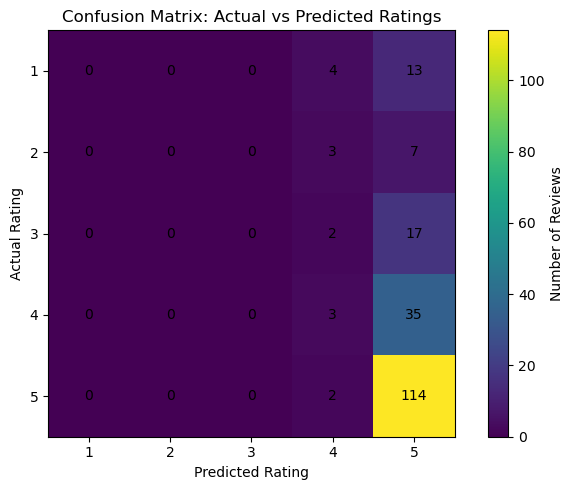

In [103]:
# Display precision, recall, F1-score, and support for each rating.
print("Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[1, 2, 3, 4, 5],
    zero_division=0
))

# Calculate the confusion matrix.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[1, 2, 3, 4, 5]
)

# Display the confusion matrix as a labelled heatmap.
plt.figure(figsize=(7, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix: Actual vs Predicted Ratings")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.xticks(range(5), [1, 2, 3, 4, 5])
plt.yticks(range(5), [1, 2, 3, 4, 5])
plt.colorbar(label="Number of Reviews")

# Add the count to each cell.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

The classification report shows that the model performs best when predicting five-star reviews, achieving a recall of 98% and an F1-score of 0.75. However, it failed to correctly identify any one-, two-, or three-star reviews and correctly identified only 8% of four-star reviews. The macro-average F1-score of 0.17 indicates poor performance across the five rating categories. Although the overall accuracy is 58%, the model relies heavily on predicting five-star ratings. This limitation may be partly due to the imbalance in the dataset, where five-star reviews make up the largest category.

### Confusion Matrix Interpretation

The confusion matrix shows that the neural network correctly classified 114 five-star reviews, demonstrating that it performs best when predicting the majority rating category. However, it struggled to identify lower-rated reviews, frequently misclassifying them as four- or five-star reviews. This suggests that the model is biased toward higher ratings, partly due to the imbalance in the dataset. The results highlight the importance of evaluating individual rating categories rather than relying on accuracy alone.

## Overall Project Reflection

This project applied Natural Language Processing (NLP), time series analysis, and neural networks to analyze customer reviews. Text preprocessing and word frequency analysis helped identify commonly discussed products and features, while time series analysis revealed changes in review activity and average ratings over time. The neural network achieved a test accuracy of 58.50%, correctly predicting 117 out of 200 reviews. However, the classification report and confusion matrix showed that the model performed best on five-star reviews and struggled to classify lower ratings. This limitation may be partly explained by the imbalance in the rating categories. Overall, the project demonstrated how data analysis and machine learning can extract useful insights from customer feedback while highlighting the importance of evaluating models beyond accuracy and improving their ability to classify underrepresented categories.